<a href="https://colab.research.google.com/github/192412566/mechine-learning-lab/blob/main/Harini_Mech_Learn_Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET
Number of samples : 150
Number of features: 4

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Classes:
0 = Setosa
1 = Not Setosa

Training samples: 120
Testing samples : 30

Logistic Regression model trained successfully!

MODEL PERFORMANCE
Accuracy: 100.0 %

Confusion Matrix:
[[10  0]
 [ 0 20]]

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Not Setosa       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


First 5 prediction probabilities:
[[3.97173556e-02 9.60282644e-01]
 [1.86678256e-03 9.98133217e-01]
 [5.20691280e-04 9.99479309e-01]
 [9.86518676e-01 1.34813239e-02]
 [1.79345197e-02 9.82065480e-01]]

NEW SAMPLE PREDICTION
New Sample: [5.1 3.5 1.4 0.2]
Probability of Setosa: 0.9827
Probabil

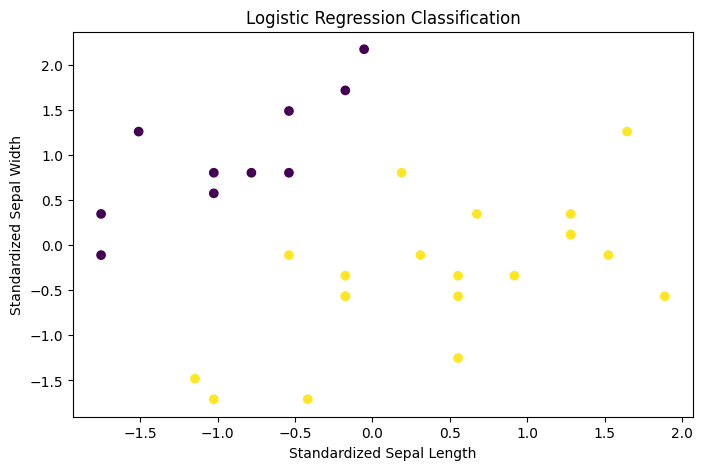

In [1]:
# ============================================================
# LOGISTIC REGRESSION (LR)
# Google Colab - No CSV Required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# ------------------------------------------------------------
# 1. Load Dataset
# ------------------------------------------------------------

iris = load_iris()

X = iris.data

# Convert into binary classification
# Setosa = 0
# Not Setosa = 1

y = (iris.target != 0).astype(int)

print("DATASET")
print("=" * 60)

print("Number of samples :", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature Names:")
print(iris.feature_names)

print("\nClasses:")
print("0 = Setosa")
print("1 = Not Setosa")


# ------------------------------------------------------------
# 2. Split Dataset
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples :", len(X_test))


# ------------------------------------------------------------
# 3. Feature Scaling
# ------------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)


# ------------------------------------------------------------
# 4. Create Logistic Regression Model
# ------------------------------------------------------------

model = LogisticRegression(
    random_state=42
)


# ------------------------------------------------------------
# 5. Train Model
# ------------------------------------------------------------

model.fit(
    X_train,
    y_train
)

print("\nLogistic Regression model trained successfully!")


# ------------------------------------------------------------
# 6. Make Predictions
# ------------------------------------------------------------

y_pred = model.predict(
    X_test
)


# ------------------------------------------------------------
# 7. Calculate Accuracy
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n" + "=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)

print(
    "Accuracy:",
    round(accuracy * 100, 2),
    "%"
)


# ------------------------------------------------------------
# 8. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 9. Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Setosa",
            "Not Setosa"
        ]
    )
)


# ------------------------------------------------------------
# 10. Predict Probability
# ------------------------------------------------------------

probabilities = model.predict_proba(
    X_test
)

print("\nFirst 5 prediction probabilities:")

print(
    probabilities[:5]
)


# ------------------------------------------------------------
# 11. Test a New Sample
# ------------------------------------------------------------

# [Sepal Length, Sepal Width, Petal Length, Petal Width]

new_sample = np.array([
    [5.1, 3.5, 1.4, 0.2]
])


# Scale sample
new_sample_scaled = scaler.transform(
    new_sample
)


# Predict class
prediction = model.predict(
    new_sample_scaled
)


# Predict probability
probability = model.predict_proba(
    new_sample_scaled
)


print("\n" + "=" * 60)
print("NEW SAMPLE PREDICTION")
print("=" * 60)

print("New Sample:", new_sample[0])

print(
    "Probability of Setosa:",
    round(float(probability[0][0]), 4)
)

print(
    "Probability of Not Setosa:",
    round(float(probability[0][1]), 4)
)

if prediction[0] == 0:
    print("Predicted Class: Setosa")
else:
    print("Predicted Class: Not Setosa")


# ------------------------------------------------------------
# 12. Visualization
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test
)

plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")

plt.title(
    "Logistic Regression Classification"
)

plt.show()